# Ablation Comparison

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 07.04.2026
- Date of Last Modification: 08.04.2026 (by Sebastian Birk (sb75@sanger.ac.uk))

## 1. Setup

### 1.1 Load Libraries 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
from pathlib import Path

### 1.2 Define Config

In [2]:
# ---------------------------------------------------------------------------
# 1. Configuration
# ---------------------------------------------------------------------------
# Each tuple: (ablation_name, model_timestamp)
ablation_timestamp_pairs = [
    ("rank",     "08042026_083724_291"),
    ("counts",   "08042026_100918_294"),
    ("combined", "21032026_085513_196"),
]

### 1.3 Configure Paths

In [3]:
base_path = Path("/nfs/team361/sb75/stjepa-reproducibility/artifacts/ablation")
results_dir = base_path / "results"
figures_dir = base_path / "figures"
results_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

### 1.4 Run Notebook Setup

In [4]:
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 9,
    "axes.labelsize": 10,
    "axes.titlesize": 11,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "legend.fontsize": 8.5,
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.05,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
})

# Shades of blue for ablation comparison
PALETTE = [
    "#023858",  # very dark navy
    "#2B8CBE",  # vivid mid blue
    "#BDD7E7",  # pale blue
]

# Prettier ablation labels for the plot (edit as needed)
ABLATION_LABELS = {
    "rank":     "Rank",
    "counts":   "Counts",
    "combined": "Combined",
}

# Panel titles and ordering (MERFISH left, STARmap right)
REGION_TITLES = {
    "ccf_region_name":             "Tissue Regions (MERFISH)",
    "Sub_molecular_tissue_region": "Tissue Regions (STARmap)",
}
REGION_ORDER = ["ccf_region_name", "Sub_molecular_tissue_region"]

### 1.5 Define Functions

In [5]:
def plot_metric_comparison(
    df: pd.DataFrame,
    metric: str,
    ablation_order: list[str],
    figsize_per_panel: tuple = (3.0, 2.4),
):
    """
    Bar plot of mean metric per ablation with individual data points overlaid.
    One panel per region_key. Text exported as editable paths for Illustrator.
    """
    region_keys = REGION_ORDER
    n_panels = len(region_keys)
    fig, axes = plt.subplots(
        1, n_panels,
        figsize=(figsize_per_panel[0] * n_panels, figsize_per_panel[1]),
        sharey=True,
        constrained_layout=True,
    )
    if n_panels == 1:
        axes = [axes]

    n_ablations = len(ablation_order)
    bar_width = 0.6
    colors = PALETTE[:n_ablations]

    for ax, rk in zip(axes, region_keys):
        sub = df[df["region_key"] == rk]

        means, sds, all_vals = [], [], []
        for a in ablation_order:
            vals = sub.loc[sub["ablation"] == a, metric].values
            means.append(np.mean(vals) if len(vals) > 0 else 0)
            sds.append(np.std(vals) if len(vals) > 0 else 0)
            all_vals.append(vals)

        x = np.arange(n_ablations)

        # --- bars (mean) ---
        ax.bar(
            x, means, width=bar_width,
            color=colors, edgecolor="white", linewidth=0.6,
            alpha=0.75, zorder=2,
        )

        # --- error bars (± 1 SD) ---
        ax.errorbar(
            x, means, yerr=sds,
            fmt="none", ecolor="0.25", elinewidth=0.8,
            capsize=2.5, capthick=0.8, zorder=3,
        )

        # --- individual data points (jittered strip) ---
        rng = np.random.default_rng(42)
        for i, vals in enumerate(all_vals):
            n_pts = len(vals)
            if n_pts == 0:
                continue
            jitter = rng.uniform(-0.15, 0.15, size=n_pts)
            ax.scatter(
                np.full(n_pts, i) + jitter, vals,
                s=12, color="0.15", edgecolor="white",
                linewidth=0.3, zorder=4, alpha=0.65,
            )

        # --- formatting ---
        pretty_rk = REGION_TITLES.get(rk, rk.replace("_", " "))
        ax.set_title(pretty_rk, fontweight="medium")
        ax.set_xticks(x)
        ax.set_xticklabels(
            [ABLATION_LABELS.get(a, a) for a in ablation_order],
            rotation=45, ha="right",
        )
        ax.set_ylabel(f"{metric} (\u2191)" if ax is axes[0] else "")
        ax.set_xlim(-0.5, n_ablations - 0.5)
        ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(5))
        ax.grid(axis="y", linewidth=0.3, alpha=0.5)

    return fig

## 2. Analysis

=== Data points per (ablation, region_key) ===
region_key  Sub_molecular_tissue_region  ccf_region_name
ablation                                                
combined                              9                9
counts                                9                9
rank                                  9                9

Saved combined dataframe to /nfs/team361/sb75/stjepa-reproducibility/artifacts/ablation/results/niche_identification_all_ablations.csv

Saved ablation_niche_NMI_comparison.svg / .pdf / .png
Saved ablation_niche_ARI_comparison.svg / .pdf / .png


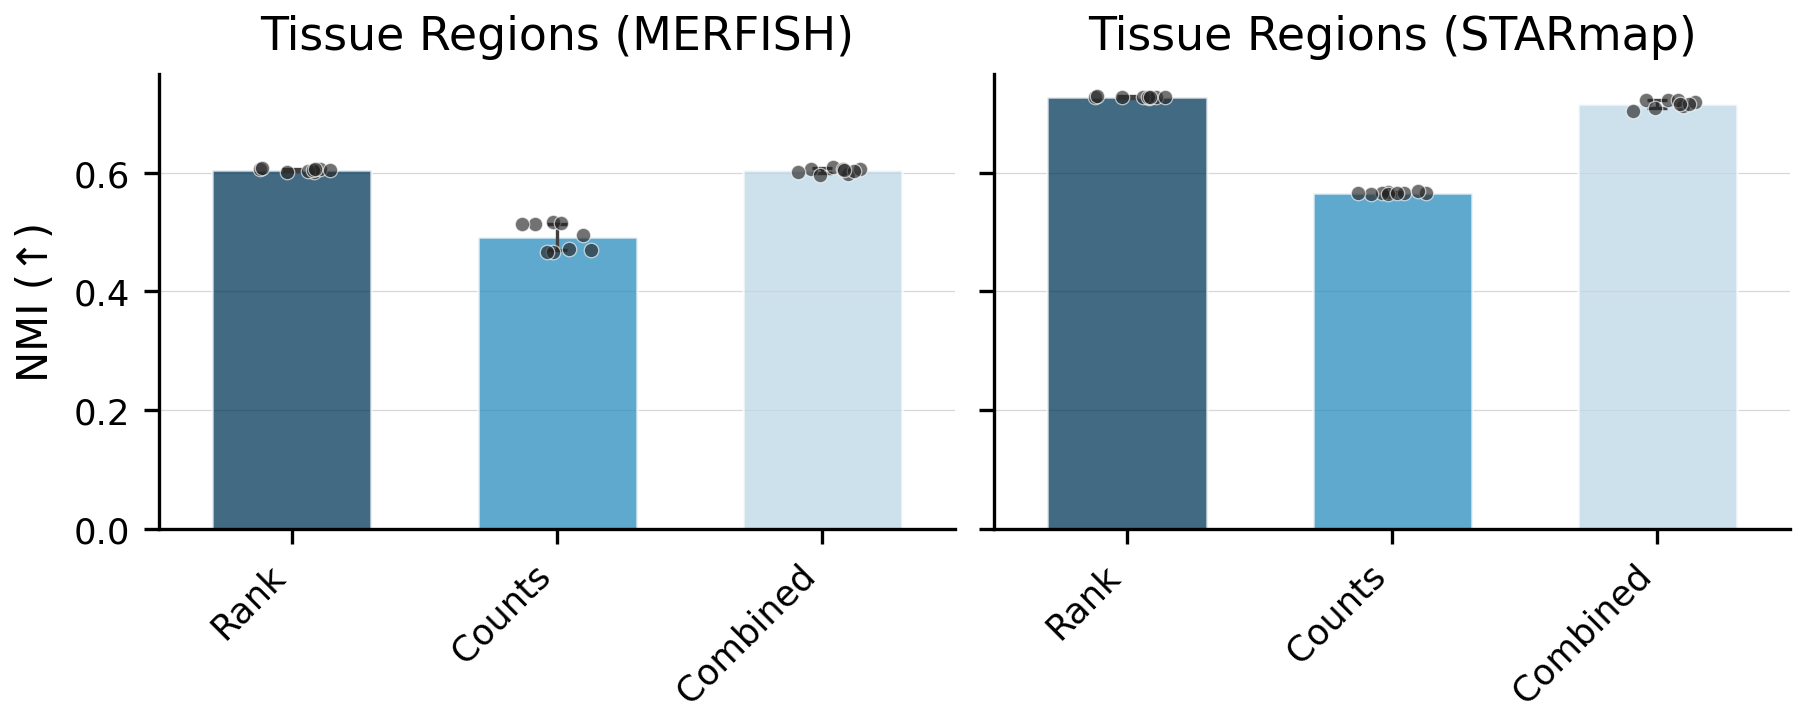

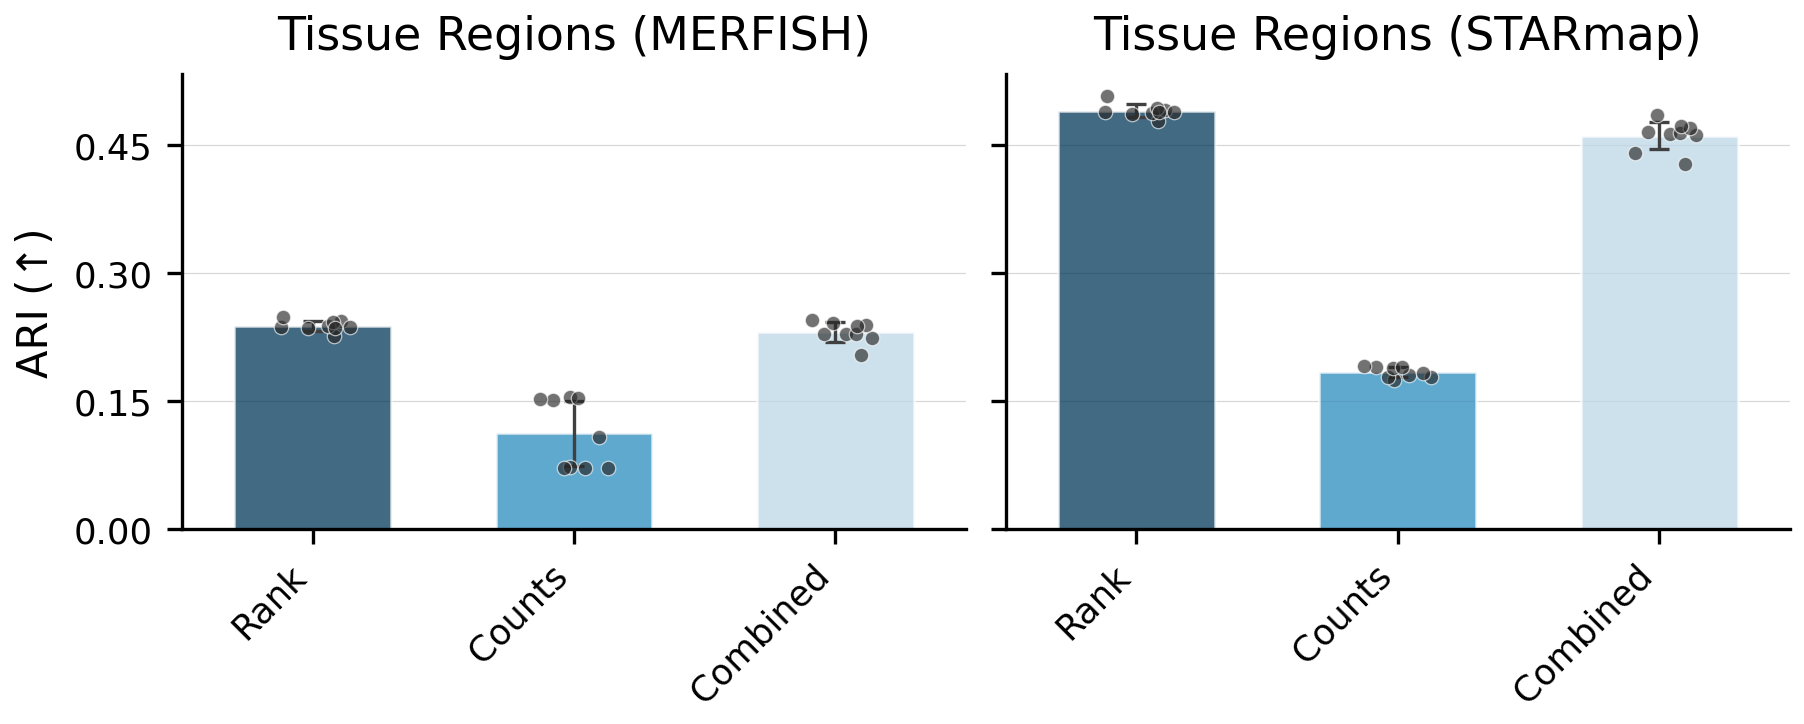


Saved batch integration dataframe to /nfs/team361/sb75/stjepa-reproducibility/artifacts/ablation/results/batch_integration_all_ablations.csv

=== Batch integration metrics ===
ablation      ASW      MMD        iLISI
combined 0.018464 0.021318 1.070867e-01
  counts 0.030855 0.025736 1.192093e-07
    rank 0.015955 0.017263 6.559348e-02
Saved ablation_batch_integration_iLISI.svg / .pdf / .png
Saved ablation_batch_integration_ASW.svg / .pdf / .png
Saved ablation_batch_integration_MMD.svg / .pdf / .png


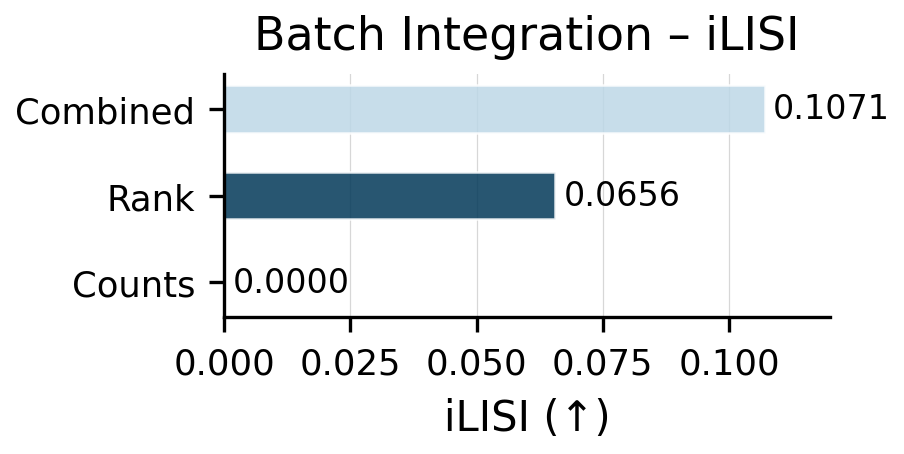

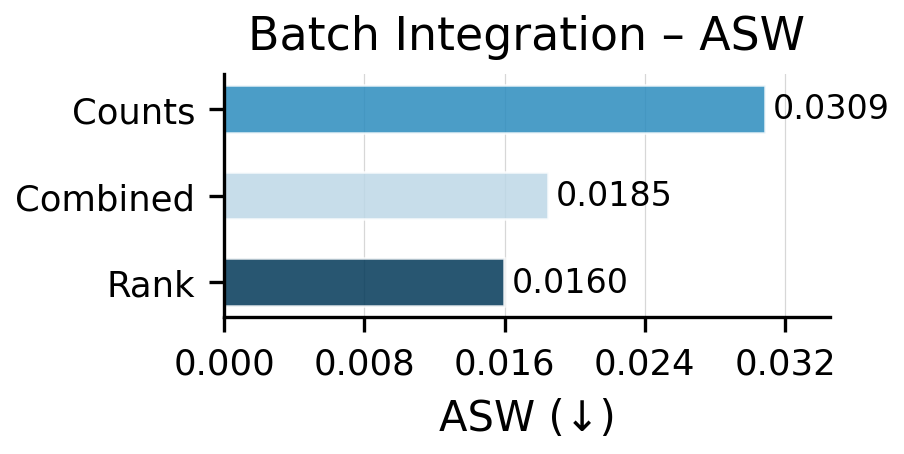

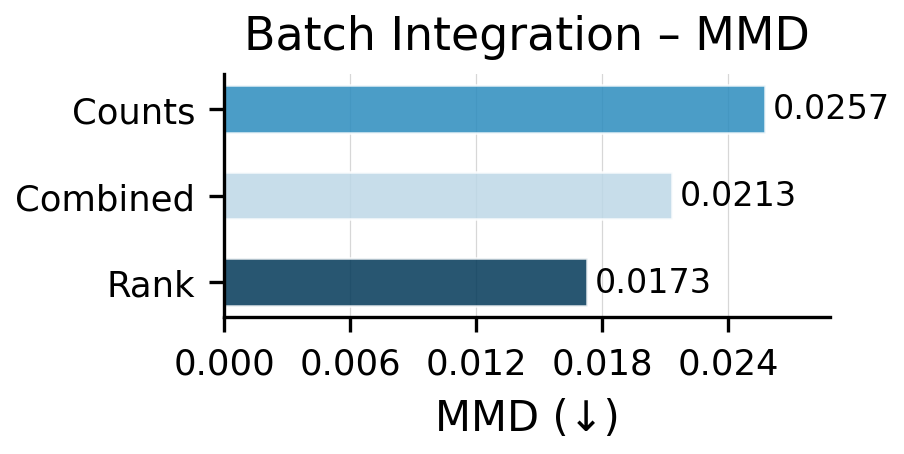

In [6]:
# ---------------------------------------------------------------------------
# 1. Load and concatenate niche identification CSVs
# ---------------------------------------------------------------------------
frames = []
for ablation, timestamp in ablation_timestamp_pairs:
    fpath = (
        base_path / f"stjepa_v2_{ablation}" / timestamp
        / "mmb0-1b_smb1-1b_1p_neighborhood_emb_niche_identification_metrics_res_sweep.csv"
    )
    if not fpath.exists():
        print(f"[WARN] File not found, skipping: {fpath}")
        continue
    df = pd.read_csv(fpath)
    df["ablation"] = ablation
    df["model_timestamp"] = timestamp
    frames.append(df)

if not frames:
    raise FileNotFoundError("No niche identification CSV files were found.")

df_all = pd.concat(frames, ignore_index=True)

# Sanity check
print("=== Data points per (ablation, region_key) ===")
print(df_all.groupby(["ablation", "region_key"]).size().unstack(fill_value=0))
print()

# Save combined dataframe
df_all.to_csv(results_dir / "niche_identification_all_ablations.csv", index=False)
print(f"Saved combined dataframe to {results_dir / 'niche_identification_all_ablations.csv'}\n")

# ---------------------------------------------------------------------------
# 2. Generate and save niche identification figures
# ---------------------------------------------------------------------------
ablation_order = [a for a, _ in ablation_timestamp_pairs]

for metric in ["NMI", "ARI"]:
    fig = plot_metric_comparison(df_all, metric=metric, ablation_order=ablation_order)
    for ext in ["svg", "pdf", "png"]:
        out = figures_dir / f"ablation_niche_{metric}_comparison.{ext}"
        fig.savefig(out)
    print(f"Saved ablation_niche_{metric}_comparison.svg / .pdf / .png")

plt.show()

# ===========================================================================
# 3. Batch integration metrics (one value per ablation)
# ===========================================================================
batch_frames = []
for ablation, timestamp in ablation_timestamp_pairs:
    fpath = (
        base_path / f"stjepa_v2_{ablation}" / timestamp
        / "mmb0-1b_smb1-1b_1p_neighborhood_emb_batch_integration_metrics.csv"
    )
    if not fpath.exists():
        print(f"[WARN] Batch file not found, skipping: {fpath}")
        continue
    df_batch = pd.read_csv(fpath)
    df_batch["ablation"] = ablation
    df_batch["model_timestamp"] = timestamp
    batch_frames.append(df_batch)

if not batch_frames:
    raise FileNotFoundError("No batch integration CSV files were found.")

df_batch_all = pd.concat(batch_frames, ignore_index=True)

# Save combined dataframe
df_batch_all.to_csv(
    results_dir / "batch_integration_all_ablations.csv", index=False
)
print(f"\nSaved batch integration dataframe to "
      f"{results_dir / 'batch_integration_all_ablations.csv'}")

# Print the table for quick inspection (wide format)
df_batch_wide = df_batch_all.pivot_table(
    index="ablation", columns="metric", values="score"
).reset_index()
print("\n=== Batch integration metrics ===")
print(df_batch_wide.to_string(index=False))

# ---------------------------------------------------------------------------
# 3b. Horizontal bar chart – one bar per ablation, sorted by metric value
# ---------------------------------------------------------------------------
# Direction indicator per batch metric
BATCH_METRIC_DIRECTION = {
    "iLISI": "\u2191",
    "ASW":   "\u2193",
    "MMD":   "\u2193",
}

ablation_order_map = {a: i for i, (a, _) in enumerate(ablation_timestamp_pairs)}
batch_metrics = df_batch_all["metric"].unique()

for bm in batch_metrics:
    df_sub = (
        df_batch_all[df_batch_all["metric"] == bm][["ablation", "score"]]
        .sort_values("score", ascending=True)
        .reset_index(drop=True)
    )

    fig, ax = plt.subplots(
        figsize=(3.0, 0.3 * len(df_sub) + 0.6),
        constrained_layout=True,
    )

    labels = [ABLATION_LABELS.get(a, a) for a in df_sub["ablation"]]
    values = df_sub["score"].astype(float).values
    y = np.arange(len(labels))

    bar_colors = [PALETTE[ablation_order_map[a]] for a in df_sub["ablation"]]

    ax.barh(
        y, values, height=0.55,
        color=bar_colors, edgecolor="white", linewidth=0.6,
        alpha=0.85, zorder=2,
    )

    # Value labels at the end of each bar
    x_max = float(np.max(values)) if len(values) > 0 else 1.0
    for yi, v in zip(y, values):
        ax.text(
            v + x_max * 0.015, yi, f"{v:.4f}",
            va="center", ha="left", fontsize=8,
        )

    ax.set_yticks(y)
    ax.set_yticklabels(labels)
    direction = BATCH_METRIC_DIRECTION.get(bm, "")
    ax.set_xlabel(f"{bm} ({direction})" if direction else bm)
    ax.set_title(f"Batch Integration – {bm}", fontweight="medium")
    ax.set_xlim(0, x_max * 1.12)
    ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(5))
    ax.grid(axis="x", linewidth=0.3, alpha=0.5)

    for ext in ["svg", "pdf", "png"]:
        out = figures_dir / f"ablation_batch_integration_{bm}.{ext}"
        fig.savefig(out)
    print(f"Saved ablation_batch_integration_{bm}.svg / .pdf / .png")

plt.show()